#### **Multiple Linear Regression**

Implementation

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# Dataset

# Features

X = np.array([
    [1,1], [2,1], [3,2], [4,2], [5,3]
])

# Target
y = np.array([250, 350, 500, 600, 750])

print("Features: ", X)
print("Targets: ", y)

Features:  [[1 1]
 [2 1]
 [3 2]
 [4 2]
 [5 3]]
Targets:  [250 350 500 600 750]


In [5]:
print("Shape of X:", X.shape)
print("Shape of y: ", y.shape)

m = X.shape[0]
print("Number of training examples: ", m)

n = X.shape[1]
print("Number of Fearures: ", n)

Shape of X: (5, 2)
Shape of y:  (5,)
Number of training examples:  5
Number of Fearures:  2


In [6]:
w = np.zeros(X.shape[1])
b = 0.0

print("Initial Weights: ", w)
print("Initial Bias: ", b)

Initial Weights:  [0. 0.]
Initial Bias:  0.0


In [ ]:
# prediction function for one sample without vectorization

def predict(x, w, b):
    return np.dot(x, w) + b

In [9]:
predictions = np.zeros(X.shape[0])

for i in range(X.shape[0]):
    predictions[i] = predict(X[i], w, b)

print("Predictions: ", predictions)

Predictions:  [0. 0. 0. 0. 0.]


In [12]:
# Vectorized Prediction

def predict_all(X, w, b):
    return np.dot(X, w) + b

In [13]:
w = np.array([100, 50])
b = 20

predictions = predict_all(X, w , b)

print("Predictions: ", predictions)

Predictions:  [170 270 420 520 670]


In [14]:
# Cost Function for multiple LR
def cost_function(X, y, w, b):

    m = X.shape[0]

    predictions = predict_all(X, w, b)

    errors = predictions - y
    squared_errors = errors ** 2
    
    total_cost = np.sum(squared_errors) / (2 * m)

    return total_cost

In [17]:
cost = cost_function(X, y, w, b)

print("Cost: ", cost)

w1 = np.array([150, 100])
b1 = 50

cost1 = cost_function(X, y, w1, b1)

print("Cost1: ", cost1)

Cost:  3200.0
Cost1:  23750.0


In [27]:
# Gradient Calculations
def gradient(X, y, w, b):
    m, n = X.shape

    predictions = predict_all(X, w, b)

    errors = predictions - y
    dj_dw = np.dot(X.T, errors) * (1/ m)
    dj_db = np.sum(errors) / m

    return dj_dw, dj_db

In [34]:
# Gradient Descent Function
def gradient_descent(X, y, w, b, a, iterations):

    costs = []
    e = 0.001

    for i in range(iterations):

        dj_dw, dj_db = gradient(X, y, w, b)

        w = w - a * dj_dw
        b = b - a * dj_db
        cost = cost_function(X, y, w, b)

        # Convergence Test
        # if (costs[i] - cost) >= e:
        #     print("Convergence !")
        #     costs.append(cost)
        #     break
        costs.append(cost)

    return costs, w, b

In [71]:
# Testing

initial_w = np.zeros(X.shape[1])
initial_b = 0.0

a = 0.01
iterations = 1000

cost_history, final_w, final_b = gradient_descent(X, y, initial_w, initial_b, a, iterations)

print("Final weights:", final_w)
print("Final bias:", final_b)
print("Final cost:", cost_history[-1])

Final weights: [96.20365508 64.24225638]
Final bias: 83.65306855793705
Final cost: 19.344239710156412


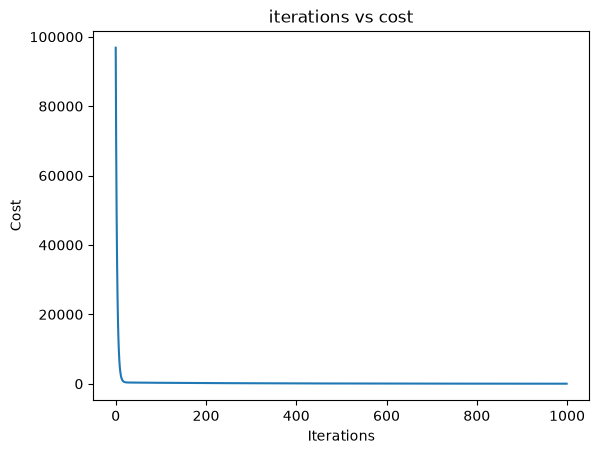

In [72]:
plt.plot(cost_history)
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("iterations vs cost")

plt.show()

In [73]:
predictions = predict_all(X, final_w, final_b)

print("Actuals: \n", y)

print("\nPredicted: \n", predictions)

Actuals: 
 [250 350 500 600 750]

Predicted: 
 [244.09898002 340.3026351  500.74854656 596.95220164 757.39811311]


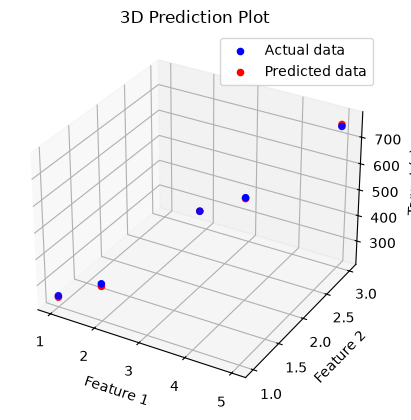

In [74]:
fig = plt.figure()
ax = plt.subplot(projection='3d')

x1 = X[:, 0]
x2 = X[:, 1]
ax.scatter3D(x1, x2, y, color='blue', label="Actual data")

ax.scatter3D(x1, x2, predictions, color='red', label="Predicted data")


ax.set_title("3D Prediction Plot")

ax.set_xlabel('Feature 1')
ax.set_ylabel('Feature 2')
ax.set_zlabel('Target (y)')

ax.legend()
plt.show()